<a href="https://colab.research.google.com/github/lovkush7/NLP--P/blob/main/AnnPassedFailed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [69]:
path ="/content/drive/MyDrive/ann_student_performance_practice.csv"

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [71]:
df = pd.read_csv(path)

In [72]:
df.shape

(3000, 11)

In [73]:
df.head()

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel,Passed
0,4.05,96.99,68.38,7.12,67.04,9,1,0.52,5.36,2,1
1,1.63,90.25,64.20,5.66,72.96,8,1,1.50,1.84,5,1
2,4.85,100.00,77.96,7.12,52.15,3,1,1.86,3.37,3,1
3,5.19,63.43,74.10,5.62,49.80,3,1,0.96,3.28,2,0
4,0.00,78.82,20.21,8.42,74.92,10,1,2.57,3.14,3,0


In [74]:
missing_percentage = (df.isnull().sum() / len(df))*100
print(missing_percentage)

StudyHoursPerDay        0.0
AttendancePercentage    0.0
PreviousExamScore       0.0
SleepHoursPerDay        0.0
AssignmentScore         0.0
ClassParticipation      0.0
InternetAccess          0.0
ExtracurricularHours    0.0
DailyScreenTimeHours    0.0
FamilySupportLevel      0.0
Passed                  0.0
dtype: float64


In [75]:
df.dtypes

,0
StudyHoursPerDay,float64
AttendancePercentage,float64
PreviousExamScore,float64
SleepHoursPerDay,float64
AssignmentScore,float64
ClassParticipation,int64
InternetAccess,int64
ExtracurricularHours,float64
DailyScreenTimeHours,float64
FamilySupportLevel,int64


In [76]:
df.describe()

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel,Passed
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,3.474773,81.727983,64.905750,6.968010,71.693057,5.039333,0.815333,2.409167,4.556587,3.040000,0.501333
std,1.767013,11.217048,14.923981,1.213132,15.421632,3.167933,0.388092,1.645207,1.816415,1.416946,0.500082
min,0.000000,35.000000,12.060000,3.080000,9.800000,0.000000,0.000000,0.050000,0.500000,1.000000,0.000000
25%,2.250000,73.947500,55.237500,6.160000,61.210000,2.000000,1.000000,1.170000,3.300000,2.000000,0.000000
50%,3.500000,82.160000,64.445000,6.940000,71.590000,5.000000,1.000000,2.070000,4.550000,3.000000,1.000000
75%,4.640000,89.850000,75.105000,7.770000,82.667500,8.000000,1.000000,3.200000,5.772500,4.000000,1.000000
max,9.220000,100.000000,100.000000,11.000000,100.000000,10.000000,1.000000,8.000000,11.130000,5.000000,1.000000


In [77]:
print("Attendance:")
print(df["AttendancePercentage"].min(), df["AttendancePercentage"].max())

print("Previous Exam:")
print(df["PreviousExamScore"].min(), df["PreviousExamScore"].max())

print("Assignment:")
print(df["AssignmentScore"].min(), df["AssignmentScore"].max())

print("Study Hours:")
print(df["StudyHoursPerDay"].min(), df["StudyHoursPerDay"].max())

print("Sleep Hours:")
print(df["SleepHoursPerDay"].min(), df["SleepHoursPerDay"].max())

Attendance:
35.0 100.0
Previous Exam:
12.06 100.0
Assignment:
9.8 100.0
Study Hours:
0.0 9.22
Sleep Hours:
3.08 11.0


In [78]:
invalid_rules = {
    "AttendancePercentage": lambda x: (x < 0) | (x > 100),
    "PreviousExamScore": lambda x: (x < 0) | (x > 100),
    "AssignmentScore": lambda x: (x < 0) | (x > 100),
    "StudyHoursPerDay": lambda x: x < 0,
    "SleepHoursPerDay": lambda x: x < 0,
    "ClassParticipation": lambda x: (x < 0) | (x > 10),
    "InternetAccess": lambda x: ~x.isin([0, 1]),
    "FamilySupportLevel": lambda x: (x < 1) | (x > 5),
    "ExtracurricularHours": lambda x: x < 0,
    "DailyScreenTimeHours": lambda x: x < 0,
    "Passed": lambda x: ~x.isin([0, 1])
}

for column, rule in invalid_rules.items():
    invalid_count = rule(df[column]).sum()
    print(f"{column}: {invalid_count} invalid values")

AttendancePercentage: 0 invalid values
PreviousExamScore: 0 invalid values
AssignmentScore: 0 invalid values
StudyHoursPerDay: 0 invalid values
SleepHoursPerDay: 0 invalid values
ClassParticipation: 0 invalid values
InternetAccess: 0 invalid values
FamilySupportLevel: 0 invalid values
ExtracurricularHours: 0 invalid values
DailyScreenTimeHours: 0 invalid values
Passed: 0 invalid values


In [79]:
print(df["Passed"].value_counts())

Passed
1    1504
0    1496
Name: count, dtype: int64


In [80]:
print(df["Passed"].value_counts(normalize=True) * 100)

Passed
1    50.133333
0    49.866667
Name: proportion, dtype: float64


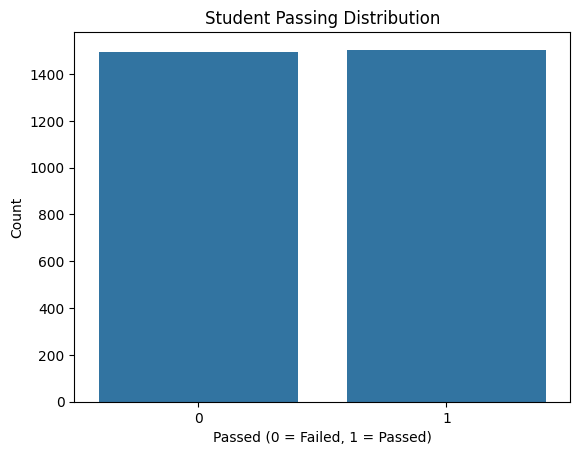

In [81]:
sns.countplot(data=df, x="Passed")

plt.title("Student Passing Distribution")
plt.xlabel("Passed (0 = Failed, 1 = Passed)")
plt.ylabel("Count")

plt.show()

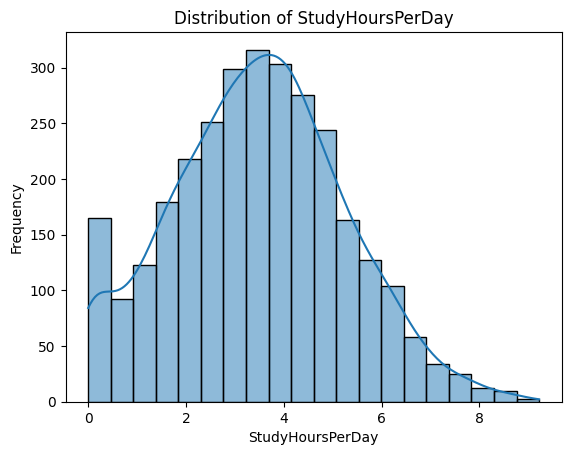

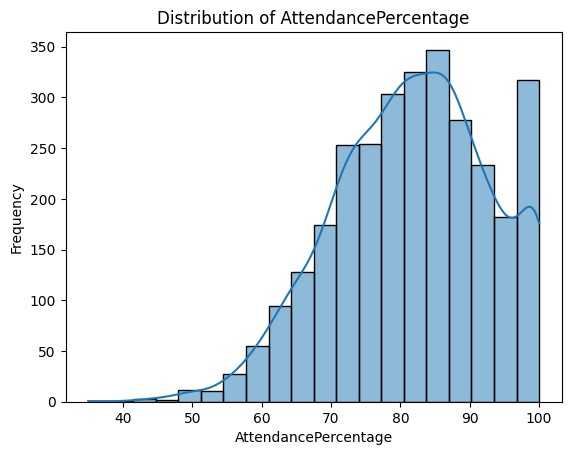

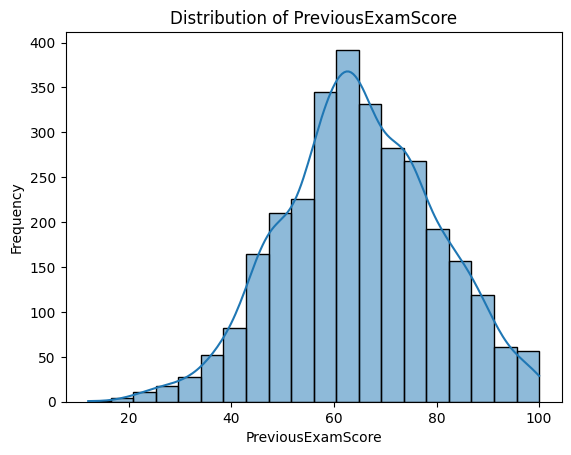

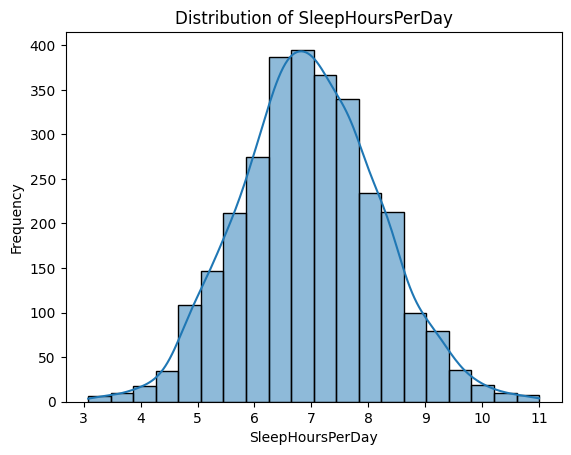

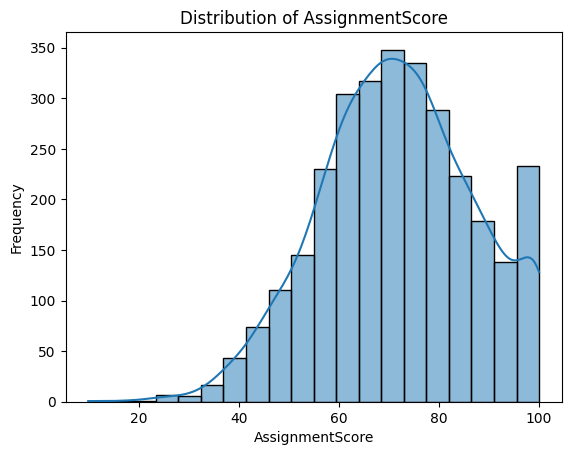

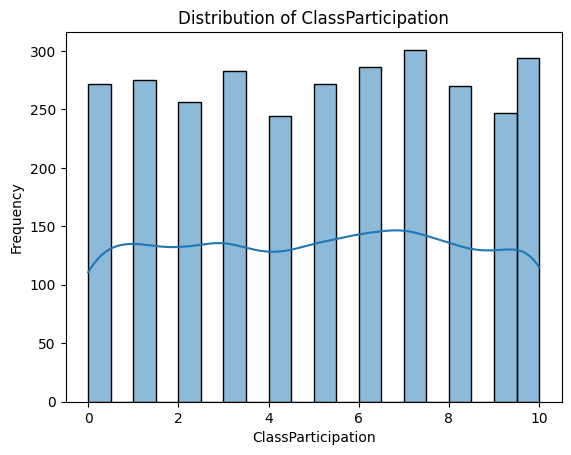

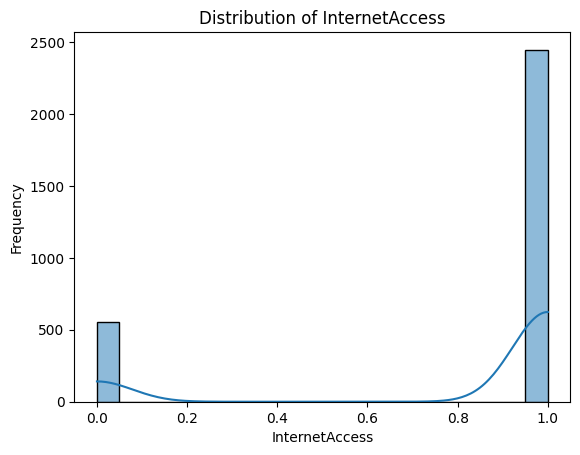

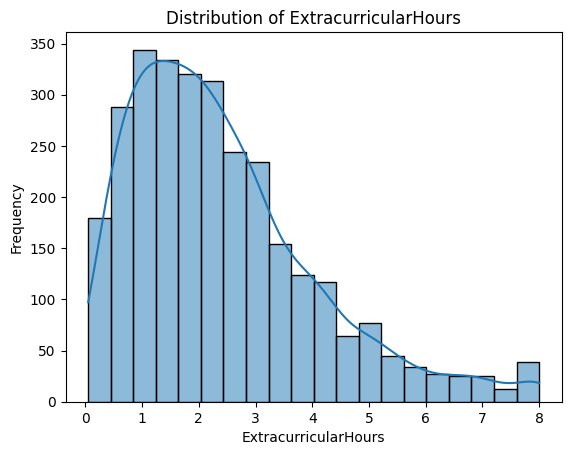

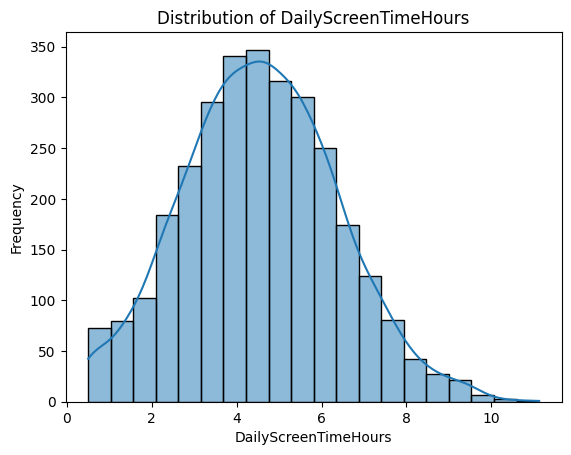

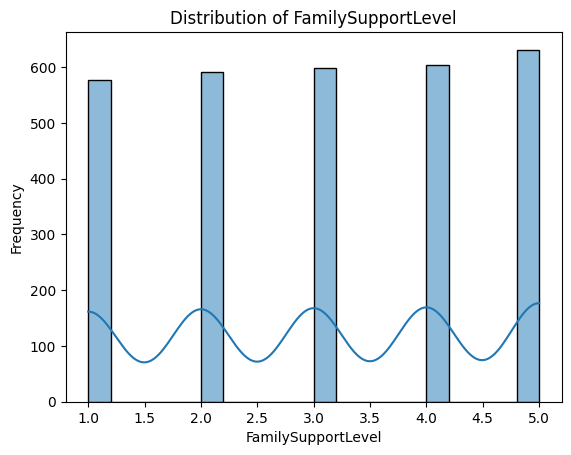

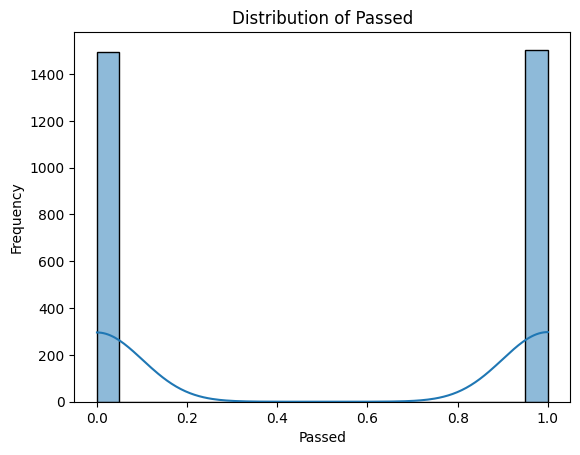

In [82]:
num_col = df.select_dtypes(include=np.number).columns
for col in num_col:
  sns.histplot(data=df, x=col, kde=True, bins=20)
  plt.title(f"Distribution of {col}")
  plt.xlabel(col)
  plt.ylabel("Frequency")
  plt.show()

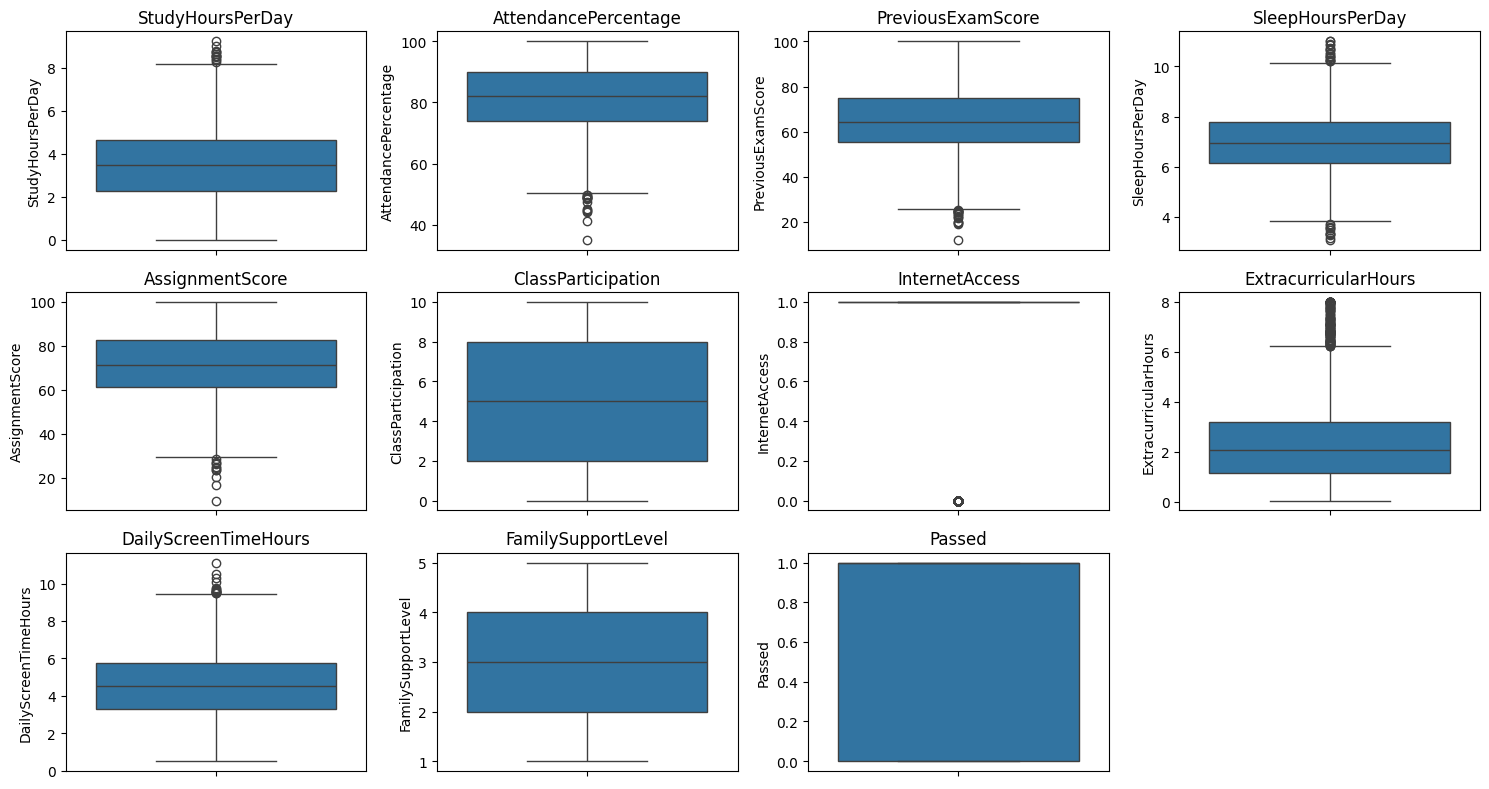

In [83]:
numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 8))

for i, column in enumerate(numeric_columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [84]:
for column in df.select_dtypes(include=np.number).columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print(f"\n{column}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Outliers:", len(outliers))


StudyHoursPerDay
Lower bound: -1.3349999999999995
Upper bound: 8.225
Outliers: 13

AttendancePercentage
Lower bound: 50.09375000000002
Upper bound: 113.70374999999999
Outliers: 15

PreviousExamScore
Lower bound: 25.43625000000001
Upper bound: 104.90624999999997
Outliers: 17

SleepHoursPerDay
Lower bound: 3.745000000000001
Upper bound: 10.184999999999999
Outliers: 30

AssignmentScore
Lower bound: 29.023750000000014
Upper bound: 114.85374999999998
Outliers: 11

ClassParticipation
Lower bound: -7.0
Upper bound: 17.0
Outliers: 0

InternetAccess
Lower bound: 1.0
Upper bound: 1.0
Outliers: 554

ExtracurricularHours
Lower bound: -1.8750000000000004
Upper bound: 6.245000000000001
Outliers: 115

DailyScreenTimeHours
Lower bound: -0.4087500000000004
Upper bound: 9.48125
Outliers: 14

FamilySupportLevel
Lower bound: -1.0
Upper bound: 7.0
Outliers: 0

Passed
Lower bound: -1.5
Upper bound: 2.5
Outliers: 0


In [85]:
print("StudyHours:", df[df["StudyHoursPerDay"] < 0])

print("Attendance:", df[df["AttendancePercentage"] > 100])

print("Previous score:", df[df["PreviousExamScore"] > 100])

print("Assignment:", df[df["AssignmentScore"] > 100])

print("InternetAccess:", df[~df["InternetAccess"].isin([0, 1])])

print("Passed:", df[~df["Passed"].isin([0, 1])])

print("Extracurricular:", df[df["ExtracurricularHours"] < 0])

print("Screen time:", df[df["DailyScreenTimeHours"] < 0])

StudyHours: Empty DataFrame
Columns: [StudyHoursPerDay, AttendancePercentage, PreviousExamScore, SleepHoursPerDay, AssignmentScore, ClassParticipation, InternetAccess, ExtracurricularHours, DailyScreenTimeHours, FamilySupportLevel, Passed]
Index: []
Attendance: Empty DataFrame
Columns: [StudyHoursPerDay, AttendancePercentage, PreviousExamScore, SleepHoursPerDay, AssignmentScore, ClassParticipation, InternetAccess, ExtracurricularHours, DailyScreenTimeHours, FamilySupportLevel, Passed]
Index: []
Previous score: Empty DataFrame
Columns: [StudyHoursPerDay, AttendancePercentage, PreviousExamScore, SleepHoursPerDay, AssignmentScore, ClassParticipation, InternetAccess, ExtracurricularHours, DailyScreenTimeHours, FamilySupportLevel, Passed]
Index: []
Assignment: Empty DataFrame
Columns: [StudyHoursPerDay, AttendancePercentage, PreviousExamScore, SleepHoursPerDay, AssignmentScore, ClassParticipation, InternetAccess, ExtracurricularHours, DailyScreenTimeHours, FamilySupportLevel, Passed]
Index:

In [86]:
df.describe()

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel,Passed
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,3.474773,81.727983,64.905750,6.968010,71.693057,5.039333,0.815333,2.409167,4.556587,3.040000,0.501333
std,1.767013,11.217048,14.923981,1.213132,15.421632,3.167933,0.388092,1.645207,1.816415,1.416946,0.500082
min,0.000000,35.000000,12.060000,3.080000,9.800000,0.000000,0.000000,0.050000,0.500000,1.000000,0.000000
25%,2.250000,73.947500,55.237500,6.160000,61.210000,2.000000,1.000000,1.170000,3.300000,2.000000,0.000000
50%,3.500000,82.160000,64.445000,6.940000,71.590000,5.000000,1.000000,2.070000,4.550000,3.000000,1.000000
75%,4.640000,89.850000,75.105000,7.770000,82.667500,8.000000,1.000000,3.200000,5.772500,4.000000,1.000000
max,9.220000,100.000000,100.000000,11.000000,100.000000,10.000000,1.000000,8.000000,11.130000,5.000000,1.000000


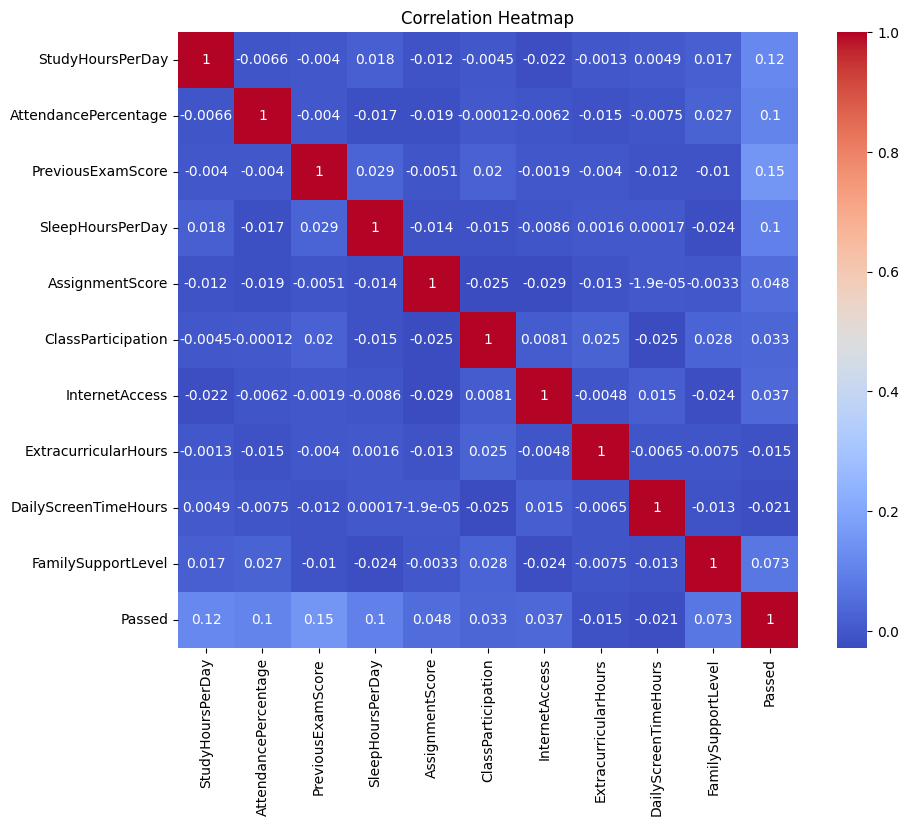

In [87]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [88]:
correlation = df.corr()["Passed"].sort_values(
    ascending=False
)

print(correlation)

Passed                  1.000000
PreviousExamScore       0.154766
StudyHoursPerDay        0.118933
AttendancePercentage    0.104633
SleepHoursPerDay        0.099744
FamilySupportLevel      0.073334
AssignmentScore         0.047586
InternetAccess          0.037349
ClassParticipation      0.032801
ExtracurricularHours   -0.015383
DailyScreenTimeHours   -0.020974
Name: Passed, dtype: float64


In [89]:
X = df.drop("Passed", axis=1)
y = df["Passed"]

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [91]:
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42, stratify=y)

In [92]:
X_train

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel
2461,1.14,80.07,67.19,8.39,75.95,6,1,2.83,2.70,3
1556,2.19,86.32,61.69,8.10,72.47,10,1,1.54,5.44,3
1225,4.44,87.03,66.71,7.52,61.91,7,1,0.10,4.01,4
1891,2.09,64.39,57.80,6.88,87.81,3,1,1.85,5.38,2
209,2.90,75.42,55.68,6.47,57.08,1,0,4.29,4.69,4
...,...,...,...,...,...,...,...,...,...,...
2900,2.49,82.62,96.65,8.31,86.91,10,1,0.99,2.33,4
1101,4.61,84.05,45.06,5.77,37.84,6,0,3.27,2.35,1
355,3.92,49.55,62.17,6.48,74.96,4,1,0.55,4.49,2
1190,6.26,94.04,57.07,6.54,51.66,0,1,2.57,2.04,1


In [93]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [94]:
X_train_scaled

array([[-1.31174396, -0.15105613,  0.15297485, ...,  0.25614957,
        -1.01855295, -0.02141705],
       [-0.72101191,  0.41203707, -0.21694795, ..., -0.52379424,
         0.49875156, -0.02141705],
       [ 0.54484248,  0.47600446,  0.12069068, ..., -1.39442919,
        -0.29312634,  0.68270504],
       ...,
       [ 0.25228947, -2.90075288, -0.18466378, ..., -1.12235577,
        -0.02732117, -0.72553913],
       [ 1.56877804,  1.1075698 , -0.52768311, ...,  0.09895159,
        -1.38403506, -1.42966122],
       [ 0.73050113, -0.79973951, -2.85348866, ..., -1.00143425,
         1.84992784,  1.38682712]], shape=(2400, 10))

In [95]:
X_train

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel
2461,1.14,80.07,67.19,8.39,75.95,6,1,2.83,2.70,3
1556,2.19,86.32,61.69,8.10,72.47,10,1,1.54,5.44,3
1225,4.44,87.03,66.71,7.52,61.91,7,1,0.10,4.01,4
1891,2.09,64.39,57.80,6.88,87.81,3,1,1.85,5.38,2
209,2.90,75.42,55.68,6.47,57.08,1,0,4.29,4.69,4
...,...,...,...,...,...,...,...,...,...,...
2900,2.49,82.62,96.65,8.31,86.91,10,1,0.99,2.33,4
1101,4.61,84.05,45.06,5.77,37.84,6,0,3.27,2.35,1
355,3.92,49.55,62.17,6.48,74.96,4,1,0.55,4.49,2
1190,6.26,94.04,57.07,6.54,51.66,0,1,2.57,2.04,1


In [97]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [98]:
model = Sequential([
    Dense(32, input_dim=X_train.shape[1], activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

In [99]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

In [100]:
history = model.fit(X_train_scaled, y_train, epochs=100, batch_size=32, validation_split=0.2 , verbose=1)

Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5250 - loss: 0.6938 - val_accuracy: 0.5146 - val_loss: 0.6941
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5865 - loss: 0.6777 - val_accuracy: 0.5500 - val_loss: 0.6869
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6016 - loss: 0.6676 - val_accuracy: 0.5750 - val_loss: 0.6807
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6094 - loss: 0.6604 - val_accuracy: 0.5917 - val_loss: 0.6767
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6052 - loss: 0.6551 - val_accuracy: 0.5938 - val_loss: 0.6717
Epoch 6/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6104 - loss: 0.6515 - val_accuracy: 0.6062 - val_loss: 0.6755
Epoch 7/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6125 - loss: 0.6488 - val_accuracy: 0.6062 - val_loss: 0.6735
Epoch 8/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6187 - loss: 0.6471 - val_accuracy: 0.6000 -

In [101]:
accuracy, loss = model.evaluate(X_test_scaled, y_test)
print("Accuracy:", accuracy)
print("Loss:", loss)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5317 - loss: 0.8180
Accuracy: 0.8179516792297363
Loss: 0.5316666960716248


In [105]:
y_pred = model.predict(X_test_scaled)
y_pred = (y_pred > 0.5).astype(int)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


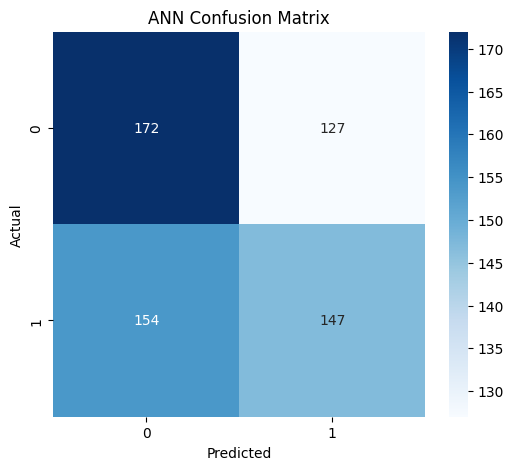

In [106]:


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")

plt.show()

In [112]:
new_student = pd.DataFrame([{
    "StudyHoursPerDay": 1,
    "AttendancePercentage": 35,
    "PreviousExamScore": 45,
    "SleepHoursPerDay": 9,
    "AssignmentScore": 60,
    "ClassParticipation": 8,
    "InternetAccess": 1,
    "ExtracurricularHours": 2,
    "DailyScreenTimeHours": 4,
    "FamilySupportLevel": 4
}])

In [108]:
new_student

,StudyHoursPerDay,AttendancePercentage,PreviousExamScore,SleepHoursPerDay,AssignmentScore,ClassParticipation,InternetAccess,ExtracurricularHours,DailyScreenTimeHours,FamilySupportLevel
0,5,85,75,7,80,8,1,2,4,4


In [113]:
new_student_scaled = scaler.transform(new_student)
prediction_probability = model.predict(new_student_scaled)

print(prediction_probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
[[0.02105084]]


In [114]:
probability = prediction_probability[0][0]

if probability >= 0.5:
    print("Student Passed")
else:
    print("Student Failed")

Student Failed
